In [1]:
import numpy as np
import ot
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [2]:
# Generate source dataset
Xs, ys = make_blobs(
    n_samples=1000,
    centers=3,
    n_features=2,
    cluster_std=0.8,
    random_state=42
)

# Generate target dataset with the same underlying classes
Xt, yt = make_blobs(
    n_samples=1000,
    centers=3,
    n_features=2,
    cluster_std=0.8,
    random_state=42
)

# Apply domain shift to target
theta = np.pi / 4

R = np.array([
    [np.cos(theta), -np.sin(theta)],
    [np.sin(theta), np.cos(theta)]
])

Xt = Xt @ R.T

# Scaling and translation
Xt = Xt * 1.5 + np.array([3, 2])

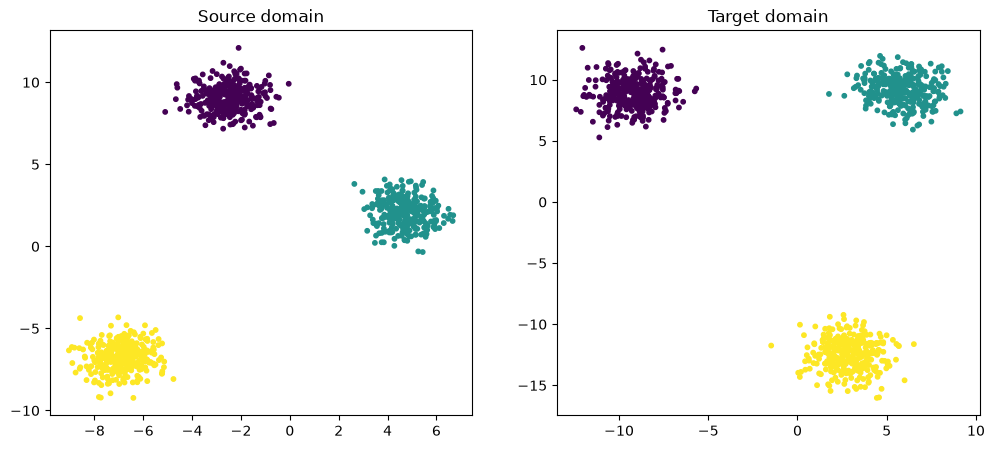

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(Xs[:, 0], Xs[:, 1], c=ys, s=10)
axes[0].set_title("Source domain")

axes[1].scatter(Xt[:, 0], Xt[:, 1], c=yt, s=10)
axes[1].set_title("Target domain")

plt.show()

In [4]:
Xs_train, Xs_test, ys_train, ys_test = train_test_split(
    Xs, ys,
    test_size=0.2,
    random_state=42,
    stratify=ys
)

Xt_train, Xt_test, yt_train, yt_test = train_test_split(
    Xt, yt,
    test_size=0.2,
    random_state=42,
    stratify=yt
)

In [5]:
baseline = LogisticRegression(
    max_iter=1000
)

baseline.fit(Xs_train, ys_train)

pred_baseline = baseline.predict(Xt_test)

baseline_accuracy = accuracy_score(
    yt_test,
    pred_baseline
)

print("Baseline accuracy:", baseline_accuracy)

Baseline accuracy: 0.68


In [6]:
# Create the transport estimator
ot_transport = ot.da.SinkhornTransport(
    reg_e=1.0,
    max_iter=1000
)

# Estimate transport using unlabeled target training data
ot_transport.fit(
    Xs=Xs_train,
    Xt=Xt_train
)

# Transform source training samples
Xs_mapped = ot_transport.transform(
    Xs=Xs_train
)

d:\DUK- Research Collab\Sanjay PhD\optimal-transport-lab\.venv\Lib\site-packages\ot\bregman\_sinkhorn.py:902: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(


In [7]:
adapted_model = LogisticRegression(
    max_iter=1000
)

adapted_model.fit(
    Xs_mapped,
    ys_train
)

pred_adapted = adapted_model.predict(Xt_test)

adapted_accuracy = accuracy_score(
    yt_test,
    pred_adapted
)

print("Baseline:", baseline_accuracy)
print("After OT adaptation:", adapted_accuracy)

Baseline: 0.68
After OT adaptation: 0.95
